In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:

years = 10
days = 365
N = years*days

def wiener_B():
    years = 10
    days = 365
    N = years*days
    time_step = 1/100
    trajectory_W = np.array([0])

    for i in range(N-1):
        increments = np.sqrt(time_step) * np.random.randn(1)
        
        trajectory_W = np.append(trajectory_W,trajectory_W[i]+increments)

    return trajectory_W


In [3]:
def year_to_daily(rate):
    return(((1+rate)**(1/365))-1)

In [4]:


def sample_active(min, max, volatility):
    half = (max-min)/2
    mu = min+half
    sig = np.sqrt(half/5)*volatility #5 standard deviations from mean
    
    W_1 = np.array(wiener_B())
    x = mu + W_1*(sig)
    x_fin = x
    for i in range(N):
        x_fin[i] = mu + (sig)*W_1[i]
        if x_fin[i] < min:
            x_fin[i] = min
        if x_fin[i] > max:
            x_fin[i] = max    
            
    
    
    return x_fin
 


<function matplotlib.pyplot.show(close=None, block=None)>

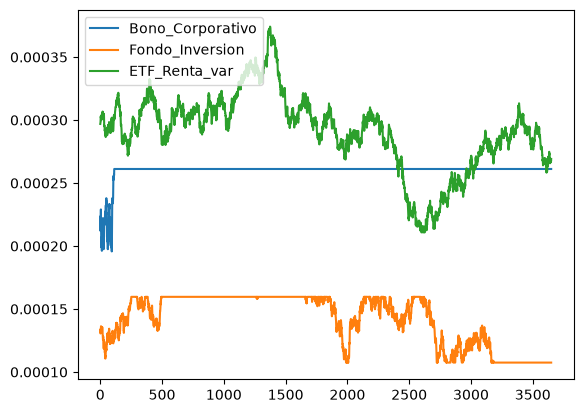

In [5]:
t = np.array([i for i in range(N)]) 
Bono_min_day = year_to_daily(0.07)
Bono_max_day = year_to_daily(0.1)   
Bono_Corporativo = sample_active(Bono_min_day, Bono_max_day,1/40)

Fondo_min_day = year_to_daily(0.04)
Fondo_max_day = year_to_daily(0.06) 
Fondo_Inversion = sample_active(Fondo_min_day, Fondo_max_day,1/100)

ETF_min_day = year_to_daily(0.08)
ETF_max_day = year_to_daily(0.15) 
ETF_Renta_var = sample_active(ETF_min_day, ETF_max_day, 1/200)
plt.plot(t,Bono_Corporativo, label = "Bono_Corporativo")
plt.plot(t,Fondo_Inversion, label = "Fondo_Inversion")
plt.plot(t,ETF_Renta_var, label = "ETF_Renta_var")
plt.legend(loc="upper left")
plt.show